# Preprocessing Teks Ulasan E-Commerce Berbahasa Indonesia

Dataset: [dipawidia/ecommerce-product-reviews-sentiment](https://huggingface.co/datasets/dipawidia/ecommerce-product-reviews-sentiment)

Alur: **muat data → info dataset → preprocessing → 10 contoh sebelum/sesudah → analisis → laporan PDF otomatis**.

> Jalankan seluruh sel dari atas ke bawah (Runtime → Run all). File `Laporan_Preprocessing.pdf` akan terbentuk di sel terakhir.

In [1]:
!pip install -q datasets PySastrawi reportlab matplotlib pandas


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## 0. Konfigurasi identitas (WAJIB diisi)

In [2]:
NAMA = "Muntasir"
NIM = "24146060"
GITHUB_URL = "https://github.com/muntasirdw46-sketch/Natural-Language-Preprocessing"

## 1. Memuat dataset

In [3]:
import pandas as pd
from datasets import load_dataset

ds = load_dataset("dipawidia/ecommerce-product-reviews-sentiment")
print(ds)
df = pd.concat([ds[s].to_pandas() for s in ds.keys()], ignore_index=True)
df.head()

C:\laragon\bin\python\python-3.10\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


DatasetDict({
    train: Dataset({
        features: ['review', 'translate', 'sentimen'],
        num_rows: 11606
    })
})


,review,translate,sentimen
0,Suara dan mic puas. Hanya saya pesan yg nyala ...,sound and mic satisfied. I only ordered the on...,0
1,Good. Mudah-mudahan awet. Makasih,good. hopefully durable. Thanks,1
2,"kondisi dus robek2, tolong di perhatikan lagi","the condition of the box is torn, please pay a...",0
3,Kualitas produk baik. Harga terjangkau dan pen...,product quality is good. affordable prices and...,0
4,"Overall bagus, tombol berfungsi semuanya, tapi...","overall is good, the buttons all work, but the...",0


## 2. Informasi dataset

Jumlah data : 11606
Kolom       : ['review', 'translate', 'sentimen']

Tipe data:
 review       object
translate    object
sentimen      int64
dtype: object

Missing value per kolom:
 review       0
translate    0
sentimen     0
dtype: int64

Duplikat pada kolom review: 7

Distribusi label sentimen:
             jumlah  persen
0 (Negatif)    5803    50.0
1 (Positif)    5803    50.0


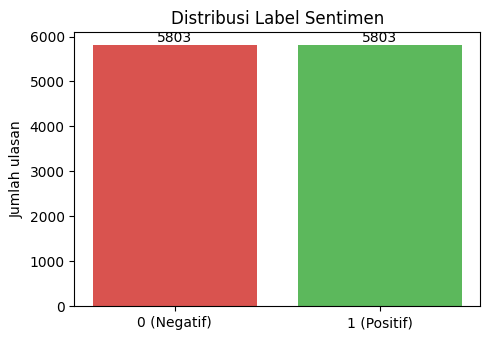

In [4]:
import matplotlib.pyplot as plt

jumlah_data = len(df)
kolom = list(df.columns)
label_map = {0: "Negatif", 1: "Positif"}
dist = df["sentimen"].value_counts().sort_index()
dist.index = [f"{i} ({label_map[i]})" for i in dist.index]
dist_pct = (dist / jumlah_data * 100).round(2)

print("Jumlah data :", jumlah_data)
print("Kolom       :", kolom)
print("\nTipe data:\n", df.dtypes)
print("\nMissing value per kolom:\n", df.isna().sum())
print("\nDuplikat pada kolom review:", df["review"].duplicated().sum())
print("\nDistribusi label sentimen:")
print(pd.DataFrame({"jumlah": dist, "persen": dist_pct}))

fig, ax = plt.subplots(figsize=(5, 3.5))
bars = ax.bar(dist.index, dist.values, color=["#d9534f", "#5cb85c"])
for b in bars:
    ax.text(b.get_x() + b.get_width()/2, b.get_height(), int(b.get_height()), ha="center", va="bottom")
ax.set_title("Distribusi Label Sentimen")
ax.set_ylabel("Jumlah ulasan")
plt.tight_layout()
plt.savefig("distribusi_label.png", dpi=150)
plt.show()

## 3. Preprocessing teks

Tahapan: **case folding → cleaning → tokenisasi → stopword removal → stemming**.

Catatan desain: kata negasi (*tidak, bukan, belum, jangan, tak, tanpa*) **dipertahankan** (dikeluarkan dari daftar stopword) karena pada analisis sentimen kata tersebut membalik makna kalimat.

In [5]:
import re
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

NEGASI = {"tidak", "bukan", "belum", "jangan", "tak", "tanpa"}
STOPWORDS = set(StopWordRemoverFactory().get_stop_words()) - NEGASI
stemmer = StemmerFactory().create_stemmer()

# 1. Case folding
def case_folding(text):
    return str(text).lower()

# 2. Cleaning: URL, mention/hashtag, angka, tanda baca, emoji & karakter khusus
def cleaning(text):
    text = re.sub(r"(https?://\S+|www\.\S+)", " ", text)   # URL
    text = re.sub(r"[@#]\w+", " ", text)                    # mention / hashtag
    text = re.sub(r"\d+", " ", text)                        # angka
    text = re.sub(r"[^a-z\s]", " ", text)                   # tanda baca, emoji, karakter khusus
    text = re.sub(r"\s+", " ", text).strip()                # spasi berlebih
    return text

# 3. Tokenisasi
def tokenize(text):
    return text.split()

# 4. Stopword removal
def remove_stopwords(tokens):
    return [t for t in tokens if t not in STOPWORDS]

# 5. Stemming (dengan cache agar cepat)
_cache = {}
def stem_tokens(tokens):
    out = []
    for t in tokens:
        if t not in _cache:
            _cache[t] = stemmer.stem(t)
        out.append(_cache[t])
    return out

def preprocess(text):
    t = case_folding(text)
    t = cleaning(t)
    tokens = tokenize(t)
    tokens = remove_stopwords(tokens)
    tokens = stem_tokens(tokens)
    return tokens

In [6]:
# Uji pada satu contoh
contoh = "Barangnya BAGUS banget!!! Pengiriman cepat, cek https://tokopedia.com 5 bintang 👍"
print("Asli     :", contoh)
print("Folding  :", case_folding(contoh))
print("Cleaning :", cleaning(case_folding(contoh)))
print("Token    :", tokenize(cleaning(case_folding(contoh))))
print("Stopword :", remove_stopwords(tokenize(cleaning(case_folding(contoh)))))
print("Stemming :", preprocess(contoh))

Asli     : Barangnya BAGUS banget!!! Pengiriman cepat, cek https://tokopedia.com 5 bintang 👍
Folding  : barangnya bagus banget!!! pengiriman cepat, cek https://tokopedia.com 5 bintang 👍
Cleaning : barangnya bagus banget pengiriman cepat cek bintang
Token    : ['barangnya', 'bagus', 'banget', 'pengiriman', 'cepat', 'cek', 'bintang']
Stopword : ['barangnya', 'bagus', 'banget', 'pengiriman', 'cepat', 'cek', 'bintang']
Stemming : ['barang', 'bagus', 'banget', 'kirim', 'cepat', 'cek', 'bintang']


In [7]:
from time import time
t0 = time()
df["tokens"] = df["review"].apply(preprocess)
df["review_clean"] = df["tokens"].apply(" ".join)
print(f"Selesai dalam {time()-t0:.1f} detik")
df[["review", "review_clean", "sentimen"]].head()

Selesai dalam 1.9 detik


,review,review_clean,sentimen
0,Suara dan mic puas. Hanya saya pesan yg nyala ...,suara mic puas pesan yg nyala sy pasti lg klik...,0
1,Good. Mudah-mudahan awet. Makasih,good mudah mudah awet makasih,1
2,"kondisi dus robek2, tolong di perhatikan lagi",kondisi dus robek tolong perhati,0
3,Kualitas produk baik. Harga terjangkau dan pen...,kualitas produk harga jangkau kirim cepet bang...,0
4,"Overall bagus, tombol berfungsi semuanya, tapi...",overall bagus tombol fungsi packaging penyot r...,0


## 4. Sepuluh contoh sebelum dan sesudah preprocessing

In [8]:
contoh10 = df.sample(10, random_state=42)[["review", "review_clean", "sentimen"]].reset_index(drop=True)
contoh10.index += 1
pd.set_option("display.max_colwidth", 200)
contoh10

,review,review_clean,sentimen
1,Barangnya original 👍. Bisa muat banyak. Gampang dipakai. Penjualnya kurang ramah,barang original muat gampang pakai jual ramah,0
2,Barang sudah sampai pengirimannya cepat,barang kirim cepat,1
3,"realpict, packing oke",realpict packing oke,1
4,Cuman bisa komen 👍👍👍,cuman komen,0
5,"mantap banget, pengiriman cepat pesan sekarang besok sudah ditangan.Desain elegan 😍. Resolusi gambar tajam 👍.",mantap banget kirim cepat pesan besok tang desain elegan resolusi gambar tajam,1
6,"awalnya dikrm hanya unit saja, setelah komplain baru dikrm dan info bonus bundling harusnya diupdate kalo tumbler dah habis..jadi tidak buat pelanggan kecewa",dikrm unit komplain dikrm info bonus bundling diupdate kalo tumbler dah habis tidak langgan kecewa,0
7,"menurut infonya free Mola TV tp ternyata perlu bayar, setelah diskusi panjang akhirnya diketahui kalau OS nya tidak diupdate...pembelian belum ada 7 hari sejak TV di terima...",info free mola tv tp bayar diskusi os tidak diupdate beli belum tv terima,0
8,Pesanan sesuai cuma syang nya gak ada saringanya buat mengkukus lain kali lebih teliti lgi ya,pesan sesuai syang gak saringanya kukus teliti lgi,0
9,remote control tidak peka,remote control tidak peka,0
10,Sudah sampai mesin cuci nya terima kasih cepat ya 5 hari sampai...kerennn,mesin cuci terima kasih cepat kerennn,1


## 5. Dampak preprocessing (statistik kuantitatif)

In [9]:
def vocab(series):
    v = set()
    for s in series:
        v.update(s)
    return v

raw_tokens = df["review"].str.split()
raw_vocab = len(vocab(raw_tokens))
clean_vocab = len(vocab(df["tokens"]))
avg_raw = raw_tokens.apply(len).mean()
avg_clean = df["tokens"].apply(len).mean()
avg_chars_raw = df["review"].str.len().mean()
avg_chars_clean = df["review_clean"].str.len().mean()
kosong = int((df["review_clean"].str.len() == 0).sum())

stats = {
    "Ukuran kosakata (unik)": (raw_vocab, clean_vocab),
    "Rata-rata jumlah kata/ulasan": (round(avg_raw, 2), round(avg_clean, 2)),
    "Rata-rata jumlah karakter/ulasan": (round(avg_chars_raw, 1), round(avg_chars_clean, 1)),
}
for k, (a, b) in stats.items():
    print(f"{k:38s} sebelum={a:<10} sesudah={b}")
print(f"\nPengurangan kosakata: {(1 - clean_vocab/raw_vocab)*100:.1f}%")
print(f"Ulasan kosong setelah preprocessing: {kosong}")

Ukuran kosakata (unik)                 sebelum=26205      sesudah=10038
Rata-rata jumlah kata/ulasan           sebelum=15.76      sesudah=11.02
Rata-rata jumlah karakter/ulasan       sebelum=103.6      sesudah=66.9

Pengurangan kosakata: 61.7%
Ulasan kosong setelah preprocessing: 20


## 6. Membuat laporan PDF otomatis

In [10]:
import re
from xml.sax.saxutils import escape
from reportlab.lib.pagesizes import A4
from reportlab.lib import colors
from reportlab.lib.units import cm
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.platypus import (SimpleDocTemplate, Paragraph, Spacer, Table,
                                TableStyle, Image, PageBreak)

def safe(text, limit=None):
    """Hapus emoji/karakter non-Latin agar tampil benar di PDF, lalu escape XML."""
    text = re.sub(r"[^\x00-\u024F]", "", str(text))
    if limit and len(text) > limit:
        text = text[:limit] + "..."
    return escape(text)

ss = getSampleStyleSheet()
body = ParagraphStyle("body", parent=ss["Normal"], fontSize=10, leading=14, alignment=4)
small = ParagraphStyle("small", parent=ss["Normal"], fontSize=7.5, leading=9.5)
h1 = ss["Heading1"]; h2 = ss["Heading2"]; title = ss["Title"]

doc = SimpleDocTemplate("Laporan_Preprocessing.pdf", pagesize=A4,
                        leftMargin=2*cm, rightMargin=2*cm, topMargin=2*cm, bottomMargin=2*cm)
S = []

S += [Paragraph("Laporan Preprocessing Teks<br/>Ulasan E-Commerce Berbahasa Indonesia", title),
      Paragraph(f"<b>Nama:</b> {safe(NAMA)} &nbsp;&nbsp; <b>NIM:</b> {safe(NIM)}", body),
      Paragraph(f'<b>GitHub:</b> <link href="{GITHUB_URL}" color="blue">{safe(GITHUB_URL)}</link>', body),
      Spacer(1, 12)]

# 1. Dataset
S.append(Paragraph("1. Dataset", h1))
S.append(Paragraph(
    "Dataset yang digunakan adalah <i>dipawidia/ecommerce-product-reviews-sentiment</i> dari Hugging Face, "
    "berisi ulasan produk dari beberapa e-commerce Indonesia (Shopee, Tokopedia, Lazada, Bukalapak, dan lainnya). "
    "Label sentimen: 1 = positif, 0 = negatif.", body))
S.append(Spacer(1, 8))

S.append(Paragraph("2. Informasi Dataset", h1))
info_rows = [["Informasi", "Nilai"],
             ["Jumlah data", f"{jumlah_data:,}"],
             ["Jumlah kolom", str(len(kolom))],
             ["Nama kolom", ", ".join(kolom)],
             ["Missing value", str(int(df[['review','sentimen']].isna().sum().sum()))],
             ["Duplikat (kolom review)", str(int(df['review'].duplicated().sum()))]]
t = Table(info_rows, colWidths=[5*cm, 11*cm])
t.setStyle(TableStyle([("BACKGROUND", (0,0), (-1,0), colors.HexColor("#2c3e50")),
                       ("TEXTCOLOR", (0,0), (-1,0), colors.white),
                       ("GRID", (0,0), (-1,-1), 0.5, colors.grey),
                       ("FONTSIZE", (0,0), (-1,-1), 9),
                       ("VALIGN", (0,0), (-1,-1), "MIDDLE")]))
S += [t, Spacer(1, 10)]

dist_rows = [["Label sentimen", "Jumlah", "Persentase"]]
for idx in dist.index:
    dist_rows.append([idx, f"{int(dist[idx]):,}", f"{dist_pct[idx]}%"])
t = Table(dist_rows, colWidths=[6*cm, 4*cm, 4*cm])
t.setStyle(TableStyle([("BACKGROUND", (0,0), (-1,0), colors.HexColor("#2c3e50")),
                       ("TEXTCOLOR", (0,0), (-1,0), colors.white),
                       ("GRID", (0,0), (-1,-1), 0.5, colors.grey),
                       ("FONTSIZE", (0,0), (-1,-1), 9)]))
S += [Paragraph("<b>Distribusi label sentimen</b>", body), Spacer(1, 4), t, Spacer(1, 8),
      Image("distribusi_label.png", width=8.5*cm, height=6*cm)]

# 3. Preprocessing
S.append(Paragraph("3. Tahapan Preprocessing", h1))
for judul, isi in [
    ("Case folding", "Seluruh teks diubah menjadi huruf kecil agar kata seperti 'Bagus' dan 'bagus' dianggap sama."),
    ("Cleaning", "Menghapus URL, mention/hashtag, angka, tanda baca, emoji, dan karakter khusus, lalu merapikan spasi."),
    ("Tokenisasi", "Memisahkan teks menjadi daftar kata berdasarkan spasi."),
    ("Stopword removal", "Menghapus kata umum (mis. 'yang', 'di', 'dan') memakai daftar stopword Sastrawi. Kata negasi "
                         "(tidak, bukan, belum, jangan, tak, tanpa) dipertahankan karena memengaruhi makna sentimen."),
    ("Stemming", "Mengubah kata ke bentuk dasar memakai Sastrawi (mis. 'pengiriman' menjadi 'kirim')."),
]:
    S.append(Paragraph(f"<b>{judul}.</b> {isi}", body))
    S.append(Spacer(1, 3))

# 4. Contoh
S.append(PageBreak())
S.append(Paragraph("4. Sepuluh Contoh Sebelum dan Sesudah Preprocessing", h1))
rows = [["No", "Label", "Sebelum", "Sesudah"]]
for i, r in contoh10.iterrows():
    rows.append([str(i), label_map[int(r["sentimen"])],
                 Paragraph(safe(r["review"], 300), small),
                 Paragraph(safe(r["review_clean"], 300) or "<i>(kosong)</i>", small)])
t = Table(rows, colWidths=[0.8*cm, 1.6*cm, 7.3*cm, 7.3*cm], repeatRows=1)
t.setStyle(TableStyle([("BACKGROUND", (0,0), (-1,0), colors.HexColor("#2c3e50")),
                       ("TEXTCOLOR", (0,0), (-1,0), colors.white),
                       ("GRID", (0,0), (-1,-1), 0.5, colors.grey),
                       ("FONTSIZE", (0,0), (-1,-1), 8),
                       ("VALIGN", (0,0), (-1,-1), "TOP")]))
S.append(t)

# 5. Pengaruh
S.append(Paragraph("5. Pengaruh Preprocessing terhadap Kualitas Data Teks", h1))
stat_rows = [["Metrik", "Sebelum", "Sesudah"]] + [[k, str(a), str(b)] for k, (a, b) in stats.items()]
t = Table(stat_rows, colWidths=[7*cm, 4*cm, 4*cm])
t.setStyle(TableStyle([("BACKGROUND", (0,0), (-1,0), colors.HexColor("#2c3e50")),
                       ("TEXTCOLOR", (0,0), (-1,0), colors.white),
                       ("GRID", (0,0), (-1,-1), 0.5, colors.grey),
                       ("FONTSIZE", (0,0), (-1,-1), 9)]))
S += [t, Spacer(1, 8)]

S.append(Paragraph(
    f"Preprocessing menurunkan ukuran kosakata dari {raw_vocab:,} menjadi {clean_vocab:,} kata unik "
    f"(berkurang {(1 - clean_vocab/raw_vocab)*100:.1f}%) dan rata-rata panjang ulasan dari {avg_raw:.1f} menjadi "
    f"{avg_clean:.1f} kata. Hal ini terjadi karena variasi penulisan (huruf besar/kecil, tanda baca, imbuhan) "
    f"disatukan menjadi bentuk yang seragam.", body))
S.append(Spacer(1, 5))
S.append(Paragraph(
    "<b>Dampak positif:</b> (1) noise seperti URL, angka, emoji, dan tanda baca hilang sehingga fitur lebih bersih; "
    "(2) dimensi fitur lebih kecil sehingga komputasi lebih efisien dan risiko <i>overfitting</i> berkurang; "
    "(3) kata berimbuhan seperti 'pengiriman' dan 'dikirim' disatukan menjadi 'kirim' sehingga frekuensi kata "
    "lebih representatif; (4) stopword yang tidak membawa makna sentimen tersingkir sehingga kata penting lebih menonjol.", body))
S.append(Spacer(1, 5))
S.append(Paragraph(
    "<b>Keterbatasan:</b> ulasan berbahasa informal/singkatan (mis. 'bgt', 'gk', 'ori') tidak selalu dikenali "
    "stemmer dan stopword list standar, sehingga normalisasi kata slang perlu ditambahkan pada penelitian lanjutan. "
    "Stemming juga dapat salah memotong kata tertentu, dan emoji yang membawa sinyal sentimen ikut hilang. "
    f"Terdapat {kosong} ulasan yang menjadi kosong setelah preprocessing (umumnya ulasan yang hanya berisi "
    "stopword, angka, atau emoji).", body))

S.append(Paragraph("6. Repositori", h1))
S.append(Paragraph(f'Kode lengkap (Jupyter Notebook) tersedia di: <link href="{GITHUB_URL}" color="blue">{safe(GITHUB_URL)}</link>', body))

doc.build(S)
print("Laporan_Preprocessing.pdf berhasil dibuat")

Laporan_Preprocessing.pdf berhasil dibuat
